# Pandas - Topic 07 - Initial Data Exploration


## Topic Objectives

- Exercise on practical approaches to start exploring your dataset


## Import Package for Learning



In [115]:
import numpy as np
import pandas as pd

## Topic 07 - Initial Data Exploration

In this notebook we will cover

- how to print information about a DataFrame using .info()
- how to quickly visualise a DataFrame with .head() or .tail()
- how to use methods to investigate DataFrame aspects with .shape, .dtypes, .columns
- how to show the unique values and number of unique values for a given variable with .unique() and .nunique(),
- how to count the number of unique rows in the DataFrame with .value_counts()
- how to use.describe() for summary statistics and .corr() for studying correlation levels

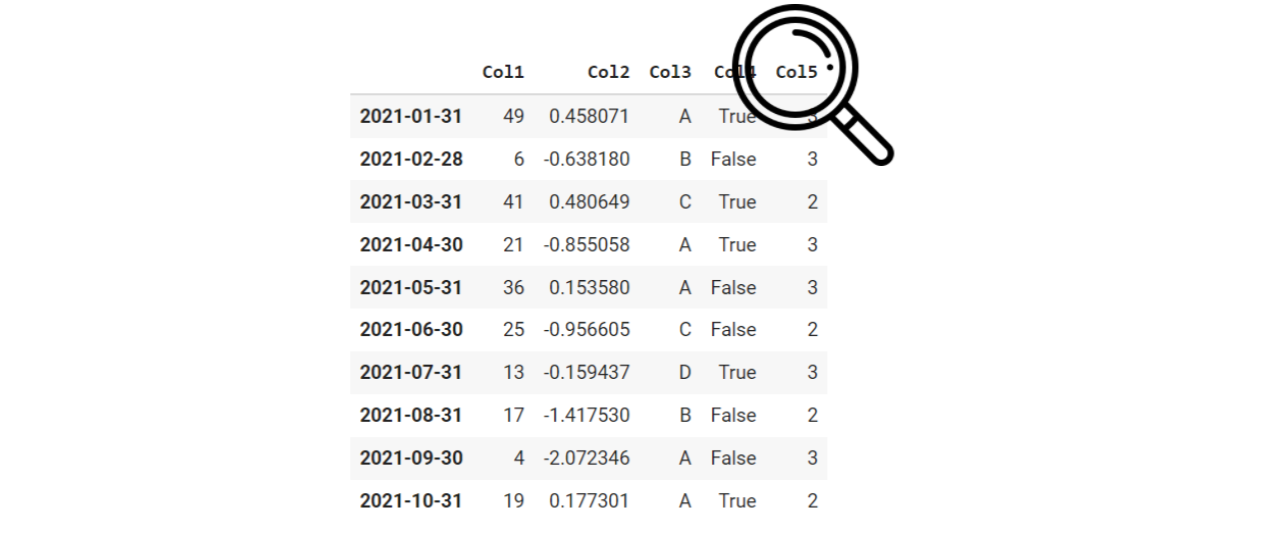


One of the most beautiful aspects of Pandas is the wide range of functions and methods dedicated to data exploration and manipulation

- You will see many examples here. We are very confident that over your career you will face and need many other use cases that we don't cover here.
- At the same time, the use cases presented here will provide you with ample examples to understand the importance of Pandas


Consider the DataFrame below, created with a Python dictionary, having four columns and content generated with NumPy array (numerical data) and Python List (categorical data)

- Col4 is a set of random boolean (True,False) generated with NumPy
- The index is made using the pd.date_range() function, where you create a series of datetime data. This function is useful when you want to create datetime data and its documentation is [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.date_range.html). In this example, we use the "start" argument as 01/01/2021, set 10 "periods" and define the period frequency with "freq" equal to "M".
   - "M" stands for month-end frequency, so the day in the dates will be the last day in that given month. For example, you will notice that for January, it will be 31, and for February, 28.
The "freq" values are also called offset-aliases and can receive different values depending on your interest, like weekly frequency, hourly frequency, month-end frequency etc. You can find the possible choices [here](https://pandas.pydata.org/pandas-docs/stable/user_guide/timeseries.html#offset-aliases).

In [116]:
df = pd.DataFrame(data={'Col1':np.random.randint(low=0,high=50,size=10),
                        'Col2':np.random.randn(10),
                        'Col3':['A','B','C','A','A','C','D','B','A','A'],
                        'Col4':np.random.choice([True, False],size=10),
                        'Col5':np.random.randint(low=1,high=4,size=10)},
                  index=pd.date_range(start='01/01/2021', periods=10, freq='M'))
df

C:\Users\zainab\AppData\Local\Temp\ipykernel_11440\2898990506.py:6: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  index=pd.date_range(start='01/01/2021', periods=10, freq='M'))


,Col1,Col2,Col3,Col4,Col5
2021-01-31,1,-0.469290,A,True,3
2021-02-28,15,-1.211589,B,False,1
2021-03-31,20,-0.906129,C,True,2
2021-04-30,26,0.139698,A,False,1
2021-05-31,20,-0.659535,A,True,1
2021-06-30,2,-0.348839,C,False,2
2021-07-31,7,-0.367998,D,True,3
2021-08-31,42,1.205503,B,True,1
2021-09-30,22,-0.084705,A,False,3
2021-10-31,37,-0.308283,A,False,3


#### .info()¶

Use the method .info() to inspect your data, in terms of the index type, range, and amount of columns and their data type and missing data levels.

- Check also the DataFrame memory usage level. The function documentation can be found [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.info.html)

In [117]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 10 entries, 2021-01-31 to 2021-10-31
Freq: ME
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Col1    10 non-null     int32  
 1   Col2    10 non-null     float64
 2   Col3    10 non-null     object 
 3   Col4    10 non-null     bool   
 4   Col5    10 non-null     int32  
dtypes: bool(1), float64(1), int32(2), object(1)
memory usage: 330.0+ bytes


**PRACTICE:** Consider the dataset below. It contains information on the relationship between personal attributes (age, gender, BMI: body mass index, family size, smoking habits), geographic factors, and their impact on medical insurance charges

In [118]:
df_practice = pd.read_csv("insurance.csv")
df_practice

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


Inspect the DataFrame, using the method we just saw.

- Can you quickly visualize (1) how many rows the DataFrame has, (2) the total amount of columns, their names and the data type for each column and (3) the memory usage? If yes, great, these are major items to be concerned with
- You will notice information for missing values (Non-null count); however, the approach described in the previous topic is easier to interpret

In [119]:
# write your code here
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 10 entries, 2021-01-31 to 2021-10-31
Freq: ME
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Col1    10 non-null     int32  
 1   Col2    10 non-null     float64
 2   Col3    10 non-null     object 
 3   Col4    10 non-null     bool   
 4   Col5    10 non-null     int32  
dtypes: bool(1), float64(1), int32(2), object(1)
memory usage: 330.0+ bytes


Rather than displaying a big dataset just to see the initial data rows, you can instead inspect the DataFrame using .head() by returning the first n rows

By default, it displays the first 5. The function documentation can be found [here](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html)


In [120]:
df.head()

,Col1,Col2,Col3,Col4,Col5
2021-01-31,1,-0.469290,A,True,3
2021-02-28,15,-1.211589,B,False,1
2021-03-31,20,-0.906129,C,True,2
2021-04-30,26,0.139698,A,False,1
2021-05-31,20,-0.659535,A,True,1


The number of rows to be displayed can also be set using the "n" argument. In this example, you want to see the first three rows

In [121]:
df.head(n=3)

,Col1,Col2,Col3,Col4,Col5
2021-01-31,1,-0.469290,A,True,3
2021-02-28,15,-1.211589,B,False,1
2021-03-31,20,-0.906129,C,True,2


Similarly, if you want to see the most recent data you can return the last n rows with .tail().

- By default, it displays the last five rows and like the previous example, you can set the n argument. The function documentation can be found [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.tail.html)

In [122]:
df.tail()

,Col1,Col2,Col3,Col4,Col5
2021-06-30,2,-0.348839,C,False,2
2021-07-31,7,-0.367998,D,True,3
2021-08-31,42,1.205503,B,True,1
2021-09-30,22,-0.084705,A,False,3
2021-10-31,37,-0.308283,A,False,3


### .shape, .dtypes and .columns¶


You can quickly get the shape (number of rows and columns) of your DataFrame using the method .shape. You will notice this method is similar to NumPy

In [123]:
df.shape

(10, 5)

In addition, you can get the data type for all variables in your data using the method .dtypes. You will notice this method is similar to NumPy

In [124]:
df.dtypes

Col1      int32
Col2    float64
Col3     object
Col4       bool
Col5      int32
dtype: object

You can get the name of the columns using the .columns method. The method documentation can be found [here](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.columns.html)

In [125]:
df.columns

Index(['Col1', 'Col2', 'Col3', 'Col4', 'Col5'], dtype='object')

You may have noticed the previous output is not a list

In [126]:
type(df.columns)

pandas.core.indexes.base.Index

Typically you want to get the name of the columns in a list format, so you can parse them into to some function.

Just parse the result into list() or add the method .to_list() to grab the result as a list. The documentation is [here](https://pandas.pydata.org/docs/reference/api/pandas.Series.to_list.html)

In [127]:
df.columns.to_list()

['Col1', 'Col2', 'Col3', 'Col4', 'Col5']

In [128]:
list(df.columns)

['Col1', 'Col2', 'Col3', 'Col4', 'Col5']

### .unique() and .nunique()¶


For a categorical variable (or, in Python, an object), you can get its unique values with .unique().

You should practice below by choosing a variable and using this method. The function documentation can be found [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.unique.html)

In [129]:
df['Col3'].unique()


array(['A', 'B', 'C', 'D'], dtype=object)

**PRACTICE:** considering df_practice, check the unique values for region

Your output should look like



In [130]:
# write your code here
df_practice['region'].unique()

array(['southwest', 'southeast', 'northwest', 'northeast'], dtype=object)

In addition, use .nunique() to count how many unique values your variable has. The function documentation can be found [here](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.nunique.html)

In [131]:
df['Col3'].nunique()

4

**PRACTICE:** considering df_practice, check how many unique values region has

In [132]:
# write the code here
df_practice['region'].nunique()

4

You can use these methods on numerical variables, but depending on the context, it may not be very informative, take the example below with Col1.

- A quick recap df

In [133]:
df

,Col1,Col2,Col3,Col4,Col5
2021-01-31,1,-0.469290,A,True,3
2021-02-28,15,-1.211589,B,False,1
2021-03-31,20,-0.906129,C,True,2
2021-04-30,26,0.139698,A,False,1
2021-05-31,20,-0.659535,A,True,1
2021-06-30,2,-0.348839,C,False,2
2021-07-31,7,-0.367998,D,True,3
2021-08-31,42,1.205503,B,True,1
2021-09-30,22,-0.084705,A,False,3
2021-10-31,37,-0.308283,A,False,3


And get the unique values for Col1

In [134]:
df["Col1"].unique()

array([ 1, 15, 20, 26,  2,  7, 42, 22, 37], dtype=int32)

### .value_counts()¶

You can return a count of unique values from a given variable with value_counts(). The function documentation can be found [here](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.value_counts.html)

In [135]:
df['Col3'].value_counts()

Col3
A    5
B    2
C    2
D    1
Name: count, dtype: int64

The previous example shows the absolute count. You can get the relative/percentual levels by setting normalize=True

In [136]:
df['Col3'].value_counts(normalize=True)

Col3
A    0.5
B    0.2
C    0.2
D    0.1
Name: proportion, dtype: float64

**PRACTICE:** considering df_practice, count the unique instances of children, then calculate in the next cell the relative levels

Your outputs should look like

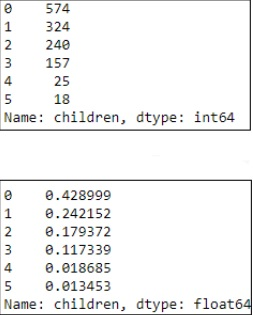


In [137]:
# write your code here: count unique instances
df_practice["children"].value_counts()

children
0    574
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64

In [138]:
# write your code here: relative frequency
df_practice["children"].value_counts(normalize=True)

children
0    0.428999
1    0.242152
2    0.179372
3    0.117339
4    0.018685
5    0.013453
Name: proportion, dtype: float64

PRACTICE: In order to test your Pandas skills, create the following DataFrame using .value_counts() on the column named: children from the DataFrame named: df_practice1

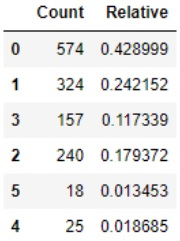


In [139]:
# write your code here - you just have to start writing: pd.DataFrame(), then fill in the parenthesis   :)
df_practice_1 = pd.DataFrame({ "Count": df_practice["children"].value_counts(),
                            "Relative": df_practice["children"].value_counts(normalize=True) })

df_practice_1

,Count,Relative
children,,
0,574,0.428999
1,324,0.242152
2,240,0.179372
3,157,0.117339
4,25,0.018685
5,18,0.013453


You can get summary statistics for your data (numerical, categorical, datetime) with the method .describe()

- There will be a dedicated lesson on how to interpret summary statistics. The function documentation can be found [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.describe.html)

In [140]:
df.describe()

,Col1,Col2,Col5
count,10.000000,10.000000,10.000000
mean,19.200000,-0.301117,2.000000
std,13.685353,0.655710,0.942809
min,1.000000,-1.211589,1.000000
25%,9.000000,-0.611974,1.000000
50%,20.000000,-0.358419,2.000000
75%,25.000000,-0.140599,3.000000
max,42.000000,1.205503,3.000000


You should add the parameter "include" and set it equal to "all" to include categorical (or objects) variables

In [141]:
df.describe(include="all")

,Col1,Col2,Col3,Col4,Col5
count,10.000000,10.000000,10,10,10.000000
unique,NaN,NaN,4,2,NaN
top,NaN,NaN,A,True,NaN
freq,NaN,NaN,5,5,NaN
mean,19.200000,-0.301117,NaN,NaN,2.000000
std,13.685353,0.655710,NaN,NaN,0.942809
min,1.000000,-1.211589,NaN,NaN,1.000000
25%,9.000000,-0.611974,NaN,NaN,1.000000
50%,20.000000,-0.358419,NaN,NaN,2.000000
75%,25.000000,-0.140599,NaN,NaN,3.000000


**PRACTICE:** calculate the summary statistics from df_practice, including all variables

Your output should look like

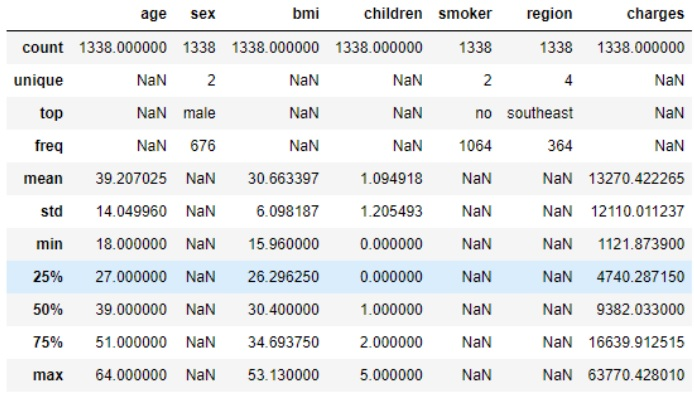


In [142]:
# write your code here
df_practice.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


### .corr()¶

You can assess correlation levels across numerical variables with .corr(). By default, the method is 'pearson', which is a measure of the linear relationship between two features

The function documentation can be found [here](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html)

In [143]:
df

,Col1,Col2,Col3,Col4,Col5
2021-01-31,1,-0.469290,A,True,3
2021-02-28,15,-1.211589,B,False,1
2021-03-31,20,-0.906129,C,True,2
2021-04-30,26,0.139698,A,False,1
2021-05-31,20,-0.659535,A,True,1
2021-06-30,2,-0.348839,C,False,2
2021-07-31,7,-0.367998,D,True,3
2021-08-31,42,1.205503,B,True,1
2021-09-30,22,-0.084705,A,False,3
2021-10-31,37,-0.308283,A,False,3


In [145]:
df.corr(numeric_only=True)

,Col1,Col2,Col4,Col5
Col1,1.000000,0.564341,-0.092428,-0.310013
Col2,0.564341,1.000000,0.099069,-0.126594
Col4,-0.092428,0.099069,1.000000,0.000000
Col5,-0.310013,-0.126594,0.000000,1.000000


You can set it by doing: method='spearman' to assess monotonic relationships (whether linear or not) in numerical variables. Monotonic is where one variable is associated with a change in the specific direction of another variable. e.g. Does a positive change in value X result in a positive change in value Y?

- There will be a dedicated lesson on how to interpret correlation levels

In [147]:
df.corr(numeric_only=True, method='spearman')

,Col1,Col2,Col4,Col5
Col1,1.000000,0.620064,-0.174608,-0.292826
Col2,0.620064,1.000000,-0.243709,0.038925
Col4,-0.174608,-0.243709,1.000000,0.000000
Col5,-0.292826,0.038925,0.000000,1.000000
